# Stellar spectroscopy

Elisavet Pavlidi · Astrophysics Laboratory, NKUA

Measure Hα across 13 stellar templates, then estimate the F0 excitation temperature from Hδ and Paδ.

This runnable version collects the same measurement functions, continuum windows and calculations from the completed laboratory notebook and its F0 addendum. The original notebook, including its saved outputs, is retained in `source/`. The report is in `report/report.pdf`.

In [1]:
from pathlib import Path
import os
import csv
import json
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

_here = Path.cwd()
_candidates = [_here, _here / "labs" / "02_stellar_spectroscopy"]
LAB_DIR = next((p for p in _candidates if (p / "pyHammer_templates").is_dir()), None)
if LAB_DIR is None:
    raise FileNotFoundError("Open this notebook from its lab folder or the repository root.")
os.chdir(LAB_DIR)
RESULTS_DIR = LAB_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)


## 1. Read the spectra

The 13 original FITS templates are included, so the analysis can run offline.

In [2]:
# Tα δεδομένα που θα χρησιμοποιήσουμε είναι από το πακέτο PyHammer, που προσδιορίζει αυτόματα το φασματικό τύπο αστέρων.
# Για το σκοπό αυτό χρησιμοποιεί πρότυπα φάσματα (templates) που θα χρησιμοποιήσουμε και σε αυτήν την άσκηση.
# Ολόκληρο το πακέτο μπορεί να βρεθεί στο https://github.com/BU-hammerTeam/PyHammer
# Κατεβάζουμε μόνο τα 13 αρχεία FITS που χρειαζόμαστε, απευθείας από το GitHub.
#https://github.com/BU-hammerTeam/PyHammer/tree/master/resources
# Προσοχή: το link "github.com/.../blob/..." δίνει ιστοσελίδα (HTML) και όχι το αρχείο. Χρειάζεται το "raw.githubusercontent.com/...".

import os
import urllib.request

URL = "https://raw.githubusercontent.com/BU-hammerTeam/PyHammer/master/resources/templates/"
DATA_DIR = "pyHammer_templates"          # φάκελος όπου αποθηκεύονται τα αρχεία
os.makedirs(DATA_DIR, exist_ok=True)

# Λεξικό: όνομα αστέρα -> όνομα αρχείου στο GitHub
# (τα O, B και A0 δεν έχουν μεταλλικότητα στο όνομα· τα υπόλοιπα είναι νάνοι με [Fe/H] = +0.0)
files = {'O5': 'O5.fits',
         'B0': 'B0.fits',
         'B5': 'B5.fits',
         'A0': 'A0.fits',
         'A6': 'A6_+0.0_Dwarf.fits',
         'F0': 'F0_+0.0_Dwarf.fits',
         'F5': 'F5_+0.0_Dwarf.fits',
         'G0': 'G0_+0.0_Dwarf.fits',
         'G5': 'G5_+0.0_Dwarf.fits',
         'K0': 'K0_+0.0_Dwarf.fits',
         'K5': 'K5_+0.0_Dwarf.fits',
         'M0': 'M0_+0.0_Dwarf.fits',
         'M5': 'M5_+0.0_Dwarf.fits'}

for star in files:
    path = os.path.join(DATA_DIR, files[star])
    if not os.path.isfile(path):                      # κατεβάζουμε μόνο αν δεν υπάρχει ήδη
        urllib.request.urlretrieve(URL + files[star], path)
    print(star, "->", path)

O5 -> pyHammer_templates/O5.fits
B0 -> pyHammer_templates/B0.fits
B5 -> pyHammer_templates/B5.fits
A0 -> pyHammer_templates/A0.fits
A6 -> pyHammer_templates/A6_+0.0_Dwarf.fits
F0 -> pyHammer_templates/F0_+0.0_Dwarf.fits
F5 -> pyHammer_templates/F5_+0.0_Dwarf.fits
G0 -> pyHammer_templates/G0_+0.0_Dwarf.fits
G5 -> pyHammer_templates/G5_+0.0_Dwarf.fits
K0 -> pyHammer_templates/K0_+0.0_Dwarf.fits
K5 -> pyHammer_templates/K5_+0.0_Dwarf.fits
M0 -> pyHammer_templates/M0_+0.0_Dwarf.fits
M5 -> pyHammer_templates/M5_+0.0_Dwarf.fits


In [3]:
# Θέλουμε να κάνουμε το ίδιο πράγμα αυτόματα - όχι n φορές για n αστέρια.
# Tα ονόματα των αστέρων, όπως και τη θερμοκρασία τους, που θα μας χρειαστεί παρακάτω, τα οργανώνουμε σε λεξικό.
# Λεξικό = μία λίστα που τα στοιχεία της τα καλούμε με το όνομα.

# Λιστα:
# stars = ["O5","B0","B5","A0","A6","F0","F5","G0","G5","K0","K5","M0","M5"]

# Λεξικό: θερμοκρασίες (K) αστέρων της κύριας ακολουθίας (νάνοι, τάξη V)
# από τον πίνακα των Pecaut & Mamajek 2013, ApJS 208, 9 (έκδοση 2022).
#https://ui.adsabs.harvard.edu/abs/2013ApJS..208....9P/abstract
# Για τα πρότυπα F, G, K θα τις αντικαταστήσουμε παρακάτω με την Teff που δίνει το ίδιο το αρχείο FITS.
stars = {'O5': 41400, 'B0': 31400, 'B5': 15700, 'A0': 9700, 'A6': 7910, 'F0': 7220, 'F5': 6550,
         'G0': 5930, 'G5': 5660, 'K0': 5270, 'K5': 4440, 'M0': 3850, 'M5': 3060}
# Από τη θεωρία, γενικά εύρη θερμοκρασίων (Κ):
# O > 30000, B 30000 – 10000, A 10000 – 7500, F 7500 – 6000, G 6000 – 5200, K 5200 – 3700, M 3700 – 2400

# Παραδειγμα
for i in stars: print(i, stars[i])

O5 41400
B0 31400
B5 15700
A0 9700
A6 7910
F0 7220
F5 6550
G0 5930
G5 5660
K0 5270
K5 4440
M0 3850
M5 3060


In [4]:
# Τώρα μπορούμε να φτιαξουμε ένα λεξικό από διδιάστατους πίνακες,
# ώστε να χρησιμοποιούμε το όνομα του κάθε αστεριού για να βρίσκουμε τα δεδομένα του.
# Σε ένα λεξικό, μπορούμε να προσθέσουμε στοιχεία ως spectra['NewQuantity']=value

spectra = {}  # κενό λεξικό

for i in stars:
    hdul = fits.open(os.path.join(DATA_DIR, files[i]))   # το πλήρες path: pyHammer_templates/....fits
    spec = hdul[1].data
    spectra[i] = (10**spec["LogLam"], spec["Flux"])     # [wavelength, flux] για κάθε αστέρι

    # Αν το αρχείο έχει Teff (πρότυπα F, G, K), τη χρησιμοποιούμε αντί για την τιμή του πίνακα
    prop = hdul[2].data
    if "Teff" in prop.columns.names:
        print(f"{i}: Teff από το FITS = {prop['Teff'][0]:.0f} K  (πίνακας: {stars[i]} K)")
        stars[i] = round(float(prop["Teff"][0]))
    else:
        print(f"{i}: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα {stars[i]} K")

O5: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 41400 K
B0: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 31400 K
B5: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 15700 K
A0: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 9700 K
A6: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 7910 K
F0: Teff από το FITS = 7585 K  (πίνακας: 7220 K)
F5: Teff από το FITS = 6260 K  (πίνακας: 6550 K)
G0: Teff από το FITS = 5869 K  (πίνακας: 5930 K)
G5: Teff από το FITS = 5655 K  (πίνακας: 5660 K)
K0: Teff από το FITS = 5444 K  (πίνακας: 5270 K)
K5: Teff από το FITS = 4596 K  (πίνακας: 4440 K)
M0: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 3850 K
M5: χωρίς Teff στο FITS, κρατάμε την τιμή του πίνακα 3060 K


In [5]:
# Ένα πρώτο plot να δουμε τα φάσματα της βιβλιοθήκης συγκρίτικά το ένα με το άλλο
from matplotlib import pyplot as plt

plt.figure(figsize=(10,6))

for i in stars:
    plt.plot(spectra[i][0], spectra[i][1]/np.mean(spectra[i][1]), label=i)
    #plt.plot(spectra[i][0], spectra[i][1], label=i)# Mπορούμε να τα πλοτάρουμε κανονικοποιημένα / μέση τιμη

plt.xlabel("Wavelength [Å]")
plt.ylabel("Flux / mean flux")
plt.legend()


## 2. Equivalent-width measurement

The original laboratory function fits a straight continuum through two windows and integrates between their inner edges. Positive equivalent width denotes absorption.

In [6]:
# Θέλουμε να εστιάσουμε σε κάποια γραμμή απορρόφησης ανά αστερι. Εδώ δίνονται τα κεντρικά μήκη κύματος βασικων φασματικών γραμμών.
# Μπορείτε να προσθέσετε γραμμές κατά το δοκούν.

# Γραμμή απορρόφησης <-> μήκος κύματος (Α) + ευρος συνεχούς πάλι εν είδει λεξικού
lines = {
    "Ha":   {"lam": 6562.8,  "cont_left": [6505,6530],  "cont_right": [6620,6645]},      # Balmer a (2→3)
    "Hb":   {"lam": 4861.3,  "cont_left": [4780,4820],  "cont_right": [4920,4950]},      # Balmer a (2→4)
    "Hg":   {"lam": 4340.5,  "cont_left": [4250,4290],  "cont_right": [4390,4440]},      # Balmer a (2→5)
    "Hd":   {"lam": 4101.7,  "cont_left": [4020,4060],  "cont_right": [4150,4190]},      # Balmer a (2→6)
    "Pa7":  {"lam": 10049,   "cont_left": [10025,10030],"cont_right": [10075,10120]},    # Paschen δ (3→7)
   }


In [7]:
def measure_line(star, line, dl=100, cont_left=None, cont_right=None, plot=True):
    # star: όνομα αστέρα, π.χ. "G0"      line: όνομα γραμμής από το λεξικό lines, π.χ. "Ha"
    # dl: μισό εύρος (Å) του κομμένου φάσματος γύρω από τη γραμμή
    # cont_left, cont_right: παράθυρα συνεχούς [Å, Å]. Αν δεν δοθούν, παίρνουμε αυτά του λεξικού lines.
    if cont_left is None:
        cont_left = lines[line]["cont_left"]
    if cont_right is None:
        cont_right = lines[line]["cont_right"]
    central_l = lines[line]["lam"]

    # 1. κόβουμε το φάσμα γύρω από τη γραμμή
    wavelength_init, flux_init = spectra[star]
    selected_range = (wavelength_init >= central_l-dl) & (wavelength_init <= central_l+dl)
    wavelength = wavelength_init[selected_range]
    flux = flux_init[selected_range]

    # 2. συνεχές: ευθεία από τη μέση ροή στα δύο παράθυρα
    in_left  = (wavelength > cont_left[0])  & (wavelength < cont_left[1])
    in_right = (wavelength > cont_right[0]) & (wavelength < cont_right[1])
    cont = in_left | in_right
    slope = (np.mean(flux[in_right]) - np.mean(flux[in_left])) / (np.mean(cont_right) - np.mean(cont_left))
    continuum = slope*(wavelength - np.mean(cont_left)) + np.mean(flux[in_left])

    # 3. ροή γραμμής, θόρυβος, S/N και equivalent width
    in_line = (wavelength > cont_left[1]) & (wavelength < cont_right[0])
    dlambda = np.gradient(wavelength)
    line_flux = np.abs(np.sum((flux[in_line] - continuum[in_line]) * dlambda[in_line]))
    noise = np.sqrt(np.sum(in_line)) * np.std(flux[cont] - continuum[cont]) * np.mean(dlambda[cont])
    EW = np.sum((1.0 - flux[in_line] / continuum[in_line]) * dlambda[in_line])

    # 4. γράφημα, ίδιο με το βήμα-βήμα παράδειγμα
    if plot:
        plt.figure(figsize=(8,4))
        plt.plot(wavelength, flux, label='data')
        plt.plot(wavelength, continuum, color='orange', label='continuum fit')
        plt.plot(wavelength[in_left],  flux[in_left],  color='orange', lw=3, label='continuum range')
        plt.plot(wavelength[in_right], flux[in_right], color='orange', lw=3)
        plt.axvline(cont_left[1], color='lightgrey')
        plt.axvline(cont_right[0], color='lightgrey')
        plt.xlabel("Wavelength [Å]")
        plt.ylabel("Flux [ 10**(-17) erg / (s * cm^2 * Å) ]")
        plt.title(f"{star}, {line}:  EW = {EW:.2f} Å,  S/N = {line_flux/noise:.0f}")
        plt.legend()
        plt.show()

    print(f"{star} {line}: flux = {line_flux:.3g} *1e-17 erg/s/cm^2,  S/N = {line_flux/noise:.1f},  EW = {EW:.2f} Å")
    return EW

## 3. Hα across spectral types

Use the continuum windows selected in the completed analysis.

O5 Ha: flux = 12.5 *1e-17 erg/s/cm^2,  S/N = 115.2,  EW = 5.23 Å
B0 Ha: flux = 11.4 *1e-17 erg/s/cm^2,  S/N = 130.1,  EW = 5.54 Å
B5 Ha: flux = 13.3 *1e-17 erg/s/cm^2,  S/N = 148.0,  EW = 6.57 Å
A0 Ha: flux = 16.4 *1e-17 erg/s/cm^2,  S/N = 88.6,  EW = 11.22 Å
A6 Ha: flux = 15.8 *1e-17 erg/s/cm^2,  S/N = 194.6,  EW = 9.54 Å
F0 Ha: flux = 12.7 *1e-17 erg/s/cm^2,  S/N = 379.9,  EW = 8.61 Å
F5 Ha: flux = 7.77 *1e-17 erg/s/cm^2,  S/N = 102.1,  EW = 4.97 Å
G0 Ha: flux = 5.77 *1e-17 erg/s/cm^2,  S/N = 222.8,  EW = 3.97 Å
G5 Ha: flux = 5.29 *1e-17 erg/s/cm^2,  S/N = 440.0,  EW = 3.76 Å
K0 Ha: flux = 4.67 *1e-17 erg/s/cm^2,  S/N = 297.6,  EW = 3.56 Å
K5 Ha: flux = 3.62 *1e-17 erg/s/cm^2,  S/N = 183.0,  EW = 3.04 Å
M0 Ha: flux = 1.9 *1e-17 erg/s/cm^2,  S/N = 334.7,  EW = 1.94 Å
M5 Ha: flux = 0.93 *1e-17 erg/s/cm^2,  S/N = 165.9,  EW = -1.98 Å
Equivalent Width of Hα:
 O5:   5.235 Å
 B0:   5.544 Å
 B5:   6.570 Å
 A0:  11.222 Å
 A6:   9.536 Å
 F0:   8.609 Å
 F5:   4.968 Å
 G0:   3.969 Å
 G5:   3.76

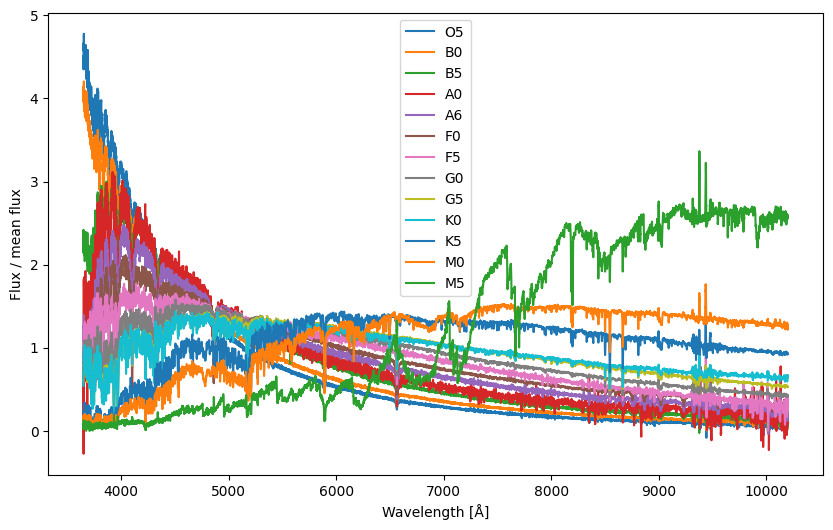

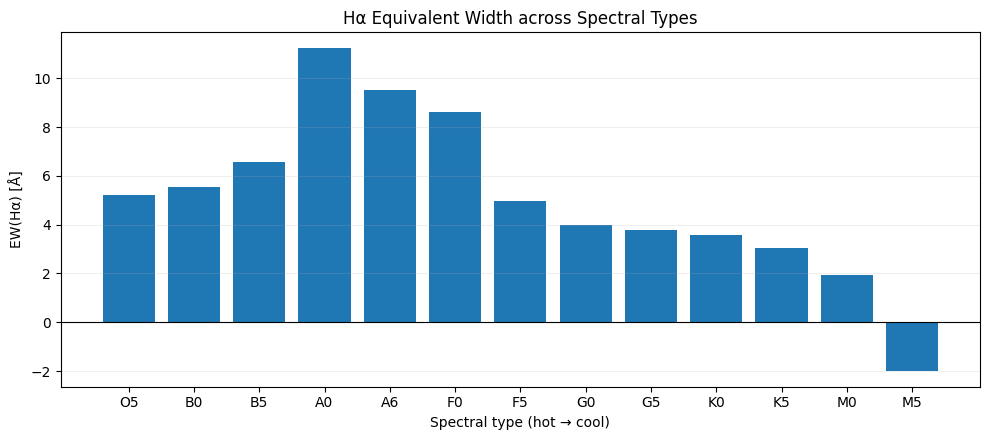

In [8]:

# EW της Hα για όλους τους φασματικούς τύπους
# Βελτιωμένα παράθυρα συνεχούς από οπτικό έλεγχο
# Ίδια ακριβώς μέθοδος υπολογισμού με το εργαστήριο

ha_windows = {
    "O5": ([6495, 6525], [6608, 6637]),
    "B0": ([6495, 6525], [6608, 6638]),
    "B5": ([6498, 6525], [6605, 6638]),
    "A0": ([6495, 6525], [6608, 6638]),
    "A6": ([6500, 6524], [6611, 6634]),
    "F0": ([6510, 6530], [6610, 6640]),
    "F5": ([6510, 6531], [6608, 6638]),
    "G0": ([6510, 6530], [6608, 6630]),
    "G5": ([6526, 6540], [6618, 6625]),
    "K0": ([6521, 6533], [6618, 6625]),
    "K5": ([6523, 6533], [6618, 6626]),
    "M0": ([6537, 6544], [6585, 6591]),
    "M5": ([6554, 6558], [6568, 6572])
}

# Υπολογισμός EW με την αρχική measure_line()
EW_Ha = {}

for star, (left, right) in ha_windows.items():
    EW_Ha[star] = measure_line(
        star,
        "Ha",
        cont_left=left,
        cont_right=right,
        plot=False
    )

# Εκτύπωση αποτελεσμάτων
print("Equivalent Width of Hα:")
for star, ew in EW_Ha.items():
    print(f"{star:>3s}: {ew:7.3f} Å")

# Διάγραμμα EW ως συνάρτηση του φασματικού τύπου
plt.figure(figsize=(10, 4.5))

plt.bar(
    list(EW_Ha.keys()),
    list(EW_Ha.values())
)

plt.xlabel("Spectral type (hot → cool)")
plt.ylabel("EW(Hα) [Å]")
plt.title("Hα Equivalent Width across Spectral Types")

plt.axhline(0, color="black", linewidth=0.8)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


In [9]:
with (RESULTS_DIR / "halpha_equivalent_widths.csv").open("w", newline="") as handle:
    writer = csv.writer(handle)
    writer.writerow(["spectral_type", "equivalent_width_A"])
    writer.writerows(EW_Ha.items())


## 4. Hδ and Paδ in F0

Use the final F0 windows and propagate the pixel-noise and shared-continuum contributions. The following cells come from the supplied F0 addendum, in dependency order.

F0 Hd: flux = 54.4 *1e-17 erg/s/cm^2,  S/N = 440.6,  EW = 15.55 Å
F0 Pa7: flux = 3.1 *1e-17 erg/s/cm^2,  S/N = 78.0,  EW = 5.27 Å
Hδ:  EW = 15.552 Å
Paδ: EW = 5.272 Å


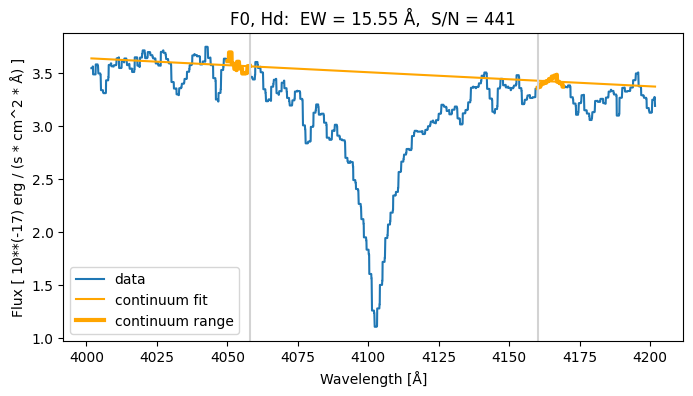

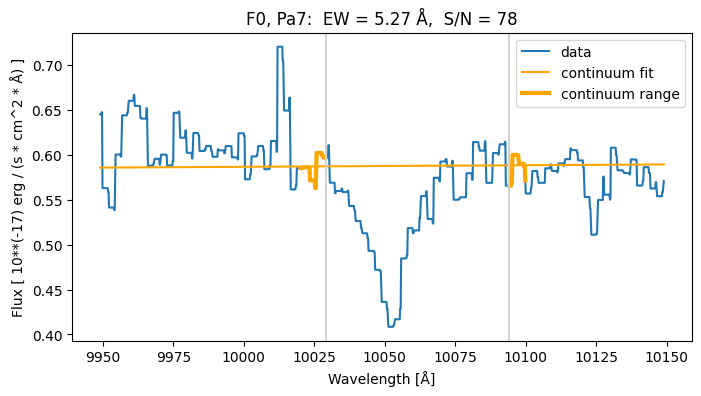

In [10]:
# F0: Οι δύο μετρήσεις EW — ίδια συνάρτηση του εργαστηρίου
F0_windows = {
    "Hd":  ([4050, 4058], [4160, 4169]),
    "Pa7": ([10020, 10029], [10094, 10100]),
}

EW_Hd = measure_line("F0", "Hd",
    cont_left=F0_windows["Hd"][0],
    cont_right=F0_windows["Hd"][1], plot=True)
EW_Pa7 = measure_line("F0", "Pa7",
    cont_left=F0_windows["Pa7"][0],
    cont_right=F0_windows["Pa7"][1], plot=True)

print(f"Hδ:  EW = {EW_Hd:.3f} Å")
print(f"Paδ: EW = {EW_Pa7:.3f} Å")

In [11]:
import numpy as np

def f0_ew_uncertainty(star, line, left, right, halfwidth=100):
    x_all, y_all = spectra[star]
    center = lines[line]["lam"]
    use = (x_all >= center-halfwidth) & (x_all <= center+halfwidth)
    x = np.asarray(x_all[use], dtype=float)
    y = np.asarray(y_all[use], dtype=float)

    l = (x > left[0]) & (x < left[1])
    r = (x > right[0]) & (x < right[1])
    w = l | r
    line_mask = (x > left[1]) & (x < right[0])
    if min(l.sum(), r.sum(), line_mask.sum()) < 2:
        raise ValueError("Πολύ λίγα σημεία στα παράθυρα / στην ολοκλήρωση")

    # ΙΔΙΟ συνεχές και ολοκλήρωμα με τη measure_line()
    xL, xR = np.mean(left), np.mean(right)
    yL, yR = y[l].mean(), y[r].mean()
    continuum = yL + (yR-yL)*(x-xL)/(xR-xL)
    dlambda = np.gradient(x)
    EW = np.sum((1-y[line_mask]/continuum[line_mask])*dlambda[line_mask])
    F = abs(np.sum((y[line_mask]-continuum[line_mask])*dlambda[line_mask]))
    sigma_pixel = np.std(y[w]-continuum[w], ddof=1)
    SN = F/(np.sqrt(line_mask.sum())*np.std(y[w]-continuum[w])*np.mean(dlambda[w]))

    # Τυπικό σφάλμα EW από τυχαίο θόρυβο στα pixels
    sigma_W_noise = np.sqrt(np.sum(
        (sigma_pixel*dlambda[line_mask]/continuum[line_mask])**2))

    # Επίδραση των αβεβαιοτήτων στη μέση ροή των ΔΥΟ παραθύρων
    alpha = (xR-x[line_mask])/(xR-xL)
    beta = 1-alpha
    dW_dyL = np.sum(y[line_mask]*dlambda[line_mask]*alpha / continuum[line_mask]**2)
    dW_dyR = np.sum(y[line_mask]*dlambda[line_mask]*beta / continuum[line_mask]**2)
    sigma_yL = np.std(y[l]-continuum[l],ddof=1)/np.sqrt(l.sum())
    sigma_yR = np.std(y[r]-continuum[r],ddof=1)/np.sqrt(r.sum())
    sigma_W_cont = np.hypot(dW_dyL*sigma_yL, dW_dyR*sigma_yR)
    sigma_W_formal = np.hypot(sigma_W_noise, sigma_W_cont)

    return dict(W=EW, F=F, SN=SN, N_left=int(l.sum()),
                N_right=int(r.sum()), sigma_noise=sigma_W_noise,
                sigma_cont=sigma_W_cont, sigma_formal=sigma_W_formal)

f0_Hd = f0_ew_uncertainty("F0", "Hd", *F0_windows["Hd"])
f0_Pa = f0_ew_uncertainty("F0", "Pa7", *F0_windows["Pa7"])
assert np.isclose(EW_Hd, f0_Hd["W"], atol=0.003)
assert np.isclose(EW_Pa7, f0_Pa["W"], atol=0.003)

for name, result in [("Hδ", f0_Hd), ("Paδ", f0_Pa)]:
    print(f'{name}: EW = {result["W"]:.3f} ± {result["sigma_formal"]:.3f} Å '
          f'(τυπική, χωρίς συστηματικά σφάλματα), S/N = {result["SN"]:.1f}, '
          f'N_cont = {result["N_left"]}+{result["N_right"]}')

Hδ: EW = 15.552 ± 0.083 Å (τυπική, χωρίς συστηματικά σφάλματα), S/N = 440.6, N_cont = 118+129
Paδ: EW = 5.272 ± 0.154 Å (τυπική, χωρίς συστηματικά σφάλματα), S/N = 78.0, N_cont = 53+35


In [12]:
# Πρόσθετος έλεγχος: τυπική συνιστώσα σφάλματος από το FITS PropErr
from astropy.io import fits
import os

with fits.open(os.path.join(DATA_DIR, files["F0"])) as hdul:
    sp = hdul[1].data
    x_fits = 10**sp["LogLam"]
    y_fits = sp["Flux"]
    prop_err = sp["PropErr"]

for name, wl, win in [("Hδ", 4101.7, F0_windows["Hd"]),
                      ("Paδ", 10049.0, F0_windows["Pa7"])]:
    L, R = win
    m = (x_fits >= wl-100) & (x_fits <= wl+100)
    x, y, e = x_fits[m], y_fits[m], prop_err[m]
    left_mask = (x > L[0]) & (x < L[1])
    right_mask = (x > R[0]) & (x < R[1])
    line_mask = (x > L[1]) & (x < R[0])
    xL, xR = np.mean(L), np.mean(R)
    yL, yR = np.mean(y[left_mask]), np.mean(y[right_mask])
    continuum = yL + (yR-yL)*(x-xL)/(xR-xL)
    dlambda = np.gradient(x)
    if not np.all(np.isfinite(e[line_mask])):
        print(name, ": μη πεπερασμένες τιμές PropErr - απαιτείται έλεγχος")
        continue
    sigma_W_prop = np.sqrt(np.sum((e[line_mask]*dlambda[line_mask]
                                   /continuum[line_mask])**2))
    print(f"{name}: σ_EW από PropErr ≈ {sigma_W_prop:.3f} Å "
          "(μόνο ανεξάρτητος θόρυβος)")

Hδ: σ_EW από PropErr ≈ 0.053 Å (μόνο ανεξάρτητος θόρυβος)
Paδ: σ_EW από PropErr ≈ 0.226 Å (μόνο ανεξάρτητος θόρυβος)


In [13]:
# Εναλλακτικά κοντινά παράθυρα, μόνο για διαγνωστικό έλεγχο
alternatives = {
    "Hd": [
        ([4050,4058], [4160,4169]),
        ([4051,4057], [4161,4168]),
        ([4050,4059], [4160,4168]),
        ([4051,4058], [4160,4169]),
        ([4048,4058], [4160,4169]),
    ],
    "Pa7": [
        ([10020,10029], [10094,10100]),
        ([10021,10029], [10094,10099]),
        ([10020,10027], [10094,10100]),
        ([10022,10030], [10094,10100]),
        ([10024,10029], [10094,10100]),
    ],
}
W_ranges = {}
for line_name, choices in alternatives.items():
    values = [f0_ew_uncertainty("F0", line_name, L, R)["W"]
              for L, R in choices]
    W_ranges[line_name] = (min(values), max(values))
    print(f"{line_name}: κοντινές επιλογές -> EW από "
          f"{min(values):.3f} ως {max(values):.3f} Å")


Hd: κοντινές επιλογές -> EW από 15.415 ως 15.602 Å
Pa7: κοντινές επιλογές -> EW από 5.074 ως 5.426 Å


In [14]:
# Φυσικές σταθερές και παράμετροι του οδηγού
lambda_Hd, lambda_Pa = 4101.7, 10049.0  # Å
osc_Hd, osc_Pa = 0.0221, 0.0277
kB_eV = 8.617333262e-5                  # eV/K
E2 = 13.6*(1-1/2**2)                    # eV
aE = 13.6*(1/2**2 - 1/3**2)              # E3-E2, eV
E3 = E2+aE
g2, g3 = 2*2**2, 2*3**2

N2_N3 = (EW_Hd/EW_Pa7)*(osc_Pa/osc_Hd)*(lambda_Pa/lambda_Hd)**2
Q = N2_N3*(g3/g2)
if Q <= 1:
    raise ValueError("Μη φυσικό αποτέλεσμα για θετική T — ελέγξτε τα EW")
T_exc = aE/(kB_eV*np.log(Q))

# Υπό ανεξάρτητες τυπικές αβεβαιότητες EW:
relN = np.hypot(f0_Hd["sigma_formal"]/EW_Hd,
                f0_Pa["sigma_formal"]/EW_Pa7)
sigma_ratio = N2_N3*relN
sigma_T_formal = T_exc/np.log(Q)*relN

print(f"E2={E2:.4f} eV, E3={E3:.4f} eV, ΔE={aE:.4f} eV")
print(f"g2={g2}, g3={g3}, N2/N3={N2_N3:.3f} ± {sigma_ratio:.3f} (τυπική)")
print(f"T_exc={T_exc:.0f} ± {sigma_T_formal:.0f} K (μόνο τυπικό σφάλμα)")
print(f"log10(W_Hδ/λ_Hδ)={np.log10(EW_Hd/lambda_Hd):.3f}")
print(f"log10(W_Paδ/λ_Paδ)={np.log10(EW_Pa7/lambda_Pa):.3f}")

# Εύρος T για συνδυασμούς των κοντινών εναλλακτικών παραθύρων
hmin,hmax = W_ranges["Hd"]
pmin,pmax = W_ranges["Pa7"]
def excitation_T(W_Hd,W_Pa):
    ratio=(W_Hd/W_Pa)*(osc_Pa/osc_Hd)*(lambda_Pa/lambda_Hd)**2
    return aE/(kB_eV*np.log(ratio*g3/g2))
t_sens = [excitation_T(h,p) for h in (hmin,hmax) for p in (pmin,pmax)]
print(f"Ευαισθησία παραθύρων: T ≈ {min(t_sens):.0f}–{max(t_sens):.0f} K")

# ΑΝΕΞΑΡΤΗΤΗ σύγκριση με θερμοκρασία αναφοράς, όχι fitting της θερμοκρασίας
print("T_eff (φυλλάδιο, F0): ~7400 K")
print("T_eff (FITs/λεξικό του οδηγού, εφόσον υπάρχει):",stars.get('F0'),"K")

E2=10.2000 eV, E3=12.0889 eV, ΔE=1.8889 eV
g2=8, g3=18, N2/N3=22.193 ± 0.658 (τυπική)
T_exc=5605 ± 42 K (μόνο τυπικό σφάλμα)
log10(W_Hδ/λ_Hδ)=-2.421
log10(W_Paδ/λ_Paδ)=-3.280
Ευαισθησία παραθύρων: T ≈ 5546–5659 K
T_eff (φυλλάδιο, F0): ~7400 K
T_eff (FITs/λεξικό του οδηγού, εφόσον υπάρχει): 7585 K


## 5. Continuum comparison

Compare the excitation-temperature estimate with the reference effective temperature. The Boltzmann estimate assumes unsaturated lines; its formal uncertainty does not include all continuum and line-formation systematics.

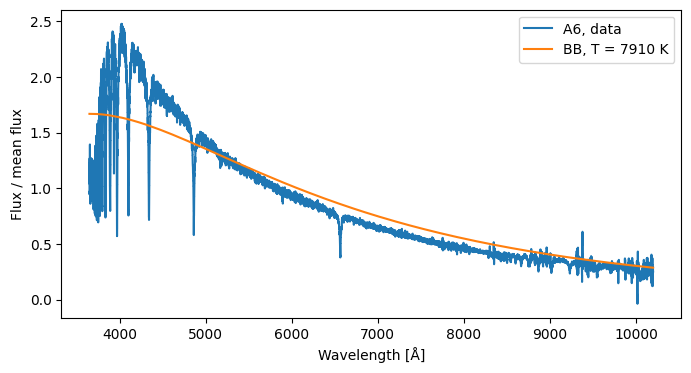

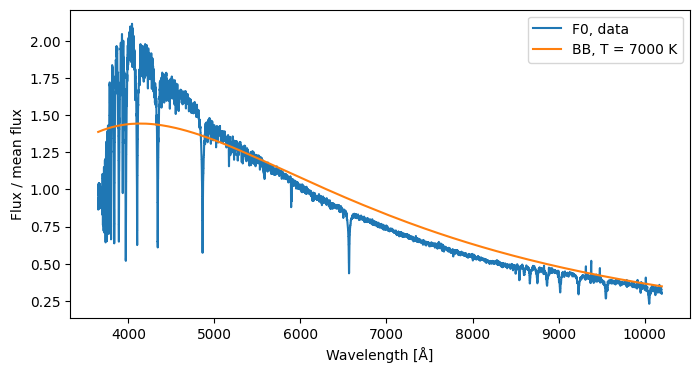

In [15]:
# Σύγκριση με θεωρητική τιμή BB

def black_body_luminosity(wavelength,T=1000): # wavelength in Angstrom
    h, c, kb = 6.626e-27, 2.9979e18, 1.381e-16    # erg s, Å/s, erg/K
    B_lambda = 2*h*c**2/ wavelength**5/(np.exp(h*c/(wavelength*kb*T))-1)
    return B_lambda/np.mean(B_lambda) # κανονικοποιημένο σχήμα (οι μονάδες δεν μας ενδιαφέρουν εδώ)

def plot_bb(star, T=None):
    # star: όνομα αστέρα      T: θερμοκρασία BB σε K. Αν δεν δοθεί, παίρνουμε τη θερμοκρασία αναφοράς stars[star]
    if T is None:
        T = stars[star]
    x = spectra[star][0]
    y = spectra[star][1]/np.mean(spectra[star][1])
    plt.figure(figsize=(8,4))
    plt.plot(x, y, label=star+", data")
    plt.plot(x, black_body_luminosity(x, T), label=f"BB, T = {T:.0f} K")
    plt.xlabel("Wavelength [Å]")
    plt.ylabel("Flux / mean flux")
    plt.legend()
    plt.show()

plot_bb("A6")             # με τη θερμοκρασία αναφοράς
plot_bb("F0", T=7000)   # καντε overplot ένα μελαν σωμα με την Τ που βρήκατε από τα EW των γραμμών του Η

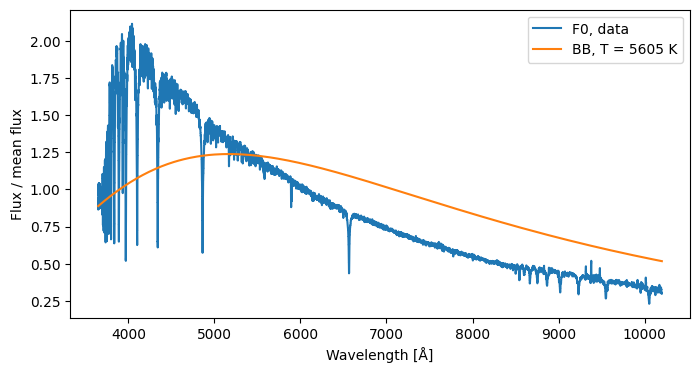

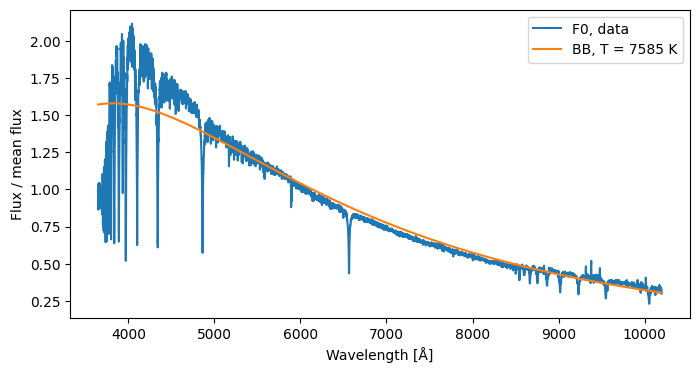

In [16]:
# Εκτέλεσέ το μόνο αφού εκτελέσεις το αρχικό κελί που ορίζει plot_bb
plot_bb("F0", T=T_exc)
plot_bb("F0", T=stars["F0"])

In [17]:
summary = {
    "Hdelta_EW_A": float(EW_Hd),
    "Paschen_delta_EW_A": float(EW_Pa7),
    "Hdelta_formal_sigma_A": float(f0_Hd["sigma_formal"]),
    "Paschen_delta_formal_sigma_A": float(f0_Pa["sigma_formal"]),
    "population_ratio_N2_over_N3": float(N2_N3),
    "excitation_temperature_K": float(T_exc),
    "excitation_temperature_formal_sigma_K": float(sigma_T_formal),
    "F0_FITS_reference_temperature_K": float(stars["F0"]),
}
(RESULTS_DIR / "f0_summary.json").write_text(json.dumps(summary, indent=2) + "\n")
summary


{'Hdelta_EW_A': 15.552144427541673, 'Paschen_delta_EW_A': 5.272103151114136, 'Hdelta_formal_sigma_A': 0.08278562873280043, 'Paschen_delta_formal_sigma_A': 0.15365527227017278, 'population_ratio_N2_over_N3': 22.19278390112775, 'excitation_temperature_K': 5605.047663782106, 'excitation_temperature_formal_sigma_K': 42.463335332891155, 'F0_FITS_reference_temperature_K': 7585.0}